一个神经元 = 线性回归（加权求和） + 激活函数（非线性变换）

In [1]:
import pandas as pd # 读数据 + 洗数据
import numpy as np # 算数据
import matplotlib.pyplot as plt # 画图工具
from sklearn.preprocessing import MinMaxScaler #归一化工具
from sklearn.model_selection import train_test_split # 划分训练集和测试集
import tensorflow as tf
from tensorflow import keras # 神经网络工具
from tensorflow.keras import layers # 全连接层
from tensorflow.keras.utils import to_categorical # 独热编码工具
from sklearn.metrics import classification_report # 分类报告工具

# 解决画图可能导致的中文显示问题
plt.rcParams['font.sans-serif'] = ['SimHei']
plt.rcParams['axes.unicode_minus'] = False

# 加载数据集
data_set = pd.read_csv("breast_cancer_clean.csv")
# print(data_set)

# 提取数据集中的特征
X = data_set.iloc[:, :-1]

# 提取数据集中的标签
Y = data_set['target']
# print(Y)

# 划分训练集和测试集
X_train, X_test, Y_train, Y_test = train_test_split(X, Y, test_size=0.2, random_state=42)

# 将数据标签转换为one-hot向量格式
Y_train_onehot = to_categorical(Y_train, 2)
Y_test_onehot = to_categorical(Y_test, 2)

# 将数据特征进行归一化
scaler = MinMaxScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)


In [2]:
# 利用keras搭建全连接神经网络
model = keras.Sequential()
model.add(layers.Dense(10, activation='relu')) # 隐藏层
model.add(layers.Dense(10, activation='relu')) # 隐藏层
model.add(layers.Dense(2, activation='softmax')) # 输出层

# 编译模型
model.compile(
    loss='categorical_crossentropy', # 交叉熵损失函数
    optimizer='SGD', # 随机梯度下降
    metrics=['accuracy'] # 评估指标
)

# 训练模型
history = model.fit(X_train_scaled, Y_train_onehot, epochs=120, batch_size=16, verbose=2, validation_data=(X_test_scaled, Y_test_onehot))
model.save('model.keras')


Epoch 1/120
29/29 - 0s - 15ms/step - accuracy: 0.5604 - loss: 0.6543 - val_accuracy: 0.7456 - val_loss: 0.6246
Epoch 2/120
29/29 - 0s - 3ms/step - accuracy: 0.8286 - loss: 0.6186 - val_accuracy: 0.9123 - val_loss: 0.5962
Epoch 3/120
29/29 - 0s - 3ms/step - accuracy: 0.8923 - loss: 0.5924 - val_accuracy: 0.9211 - val_loss: 0.5717
Epoch 4/120
29/29 - 0s - 3ms/step - accuracy: 0.8989 - loss: 0.5693 - val_accuracy: 0.9386 - val_loss: 0.5476
Epoch 5/120
29/29 - 0s - 3ms/step - accuracy: 0.9143 - loss: 0.5463 - val_accuracy: 0.9211 - val_loss: 0.5244
Epoch 6/120
29/29 - 0s - 3ms/step - accuracy: 0.9143 - loss: 0.5240 - val_accuracy: 0.9298 - val_loss: 0.5010
Epoch 7/120
29/29 - 0s - 2ms/step - accuracy: 0.9231 - loss: 0.5015 - val_accuracy: 0.9298 - val_loss: 0.4778
Epoch 8/120
29/29 - 0s - 3ms/step - accuracy: 0.9275 - loss: 0.4793 - val_accuracy: 0.9298 - val_loss: 0.4551
Epoch 9/120
29/29 - 0s - 2ms/step - accuracy: 0.9253 - loss: 0.4575 - val_accuracy: 0.9474 - val_loss: 0.4329
Epoch 10/

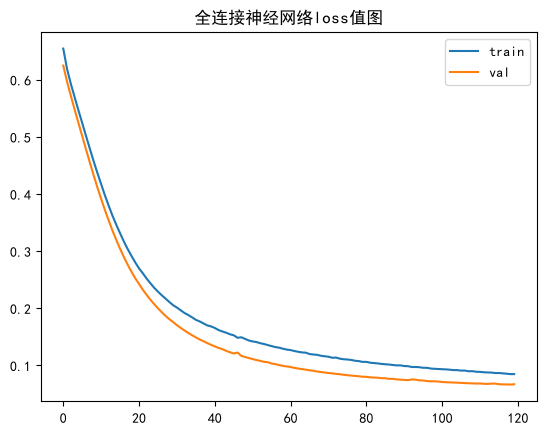

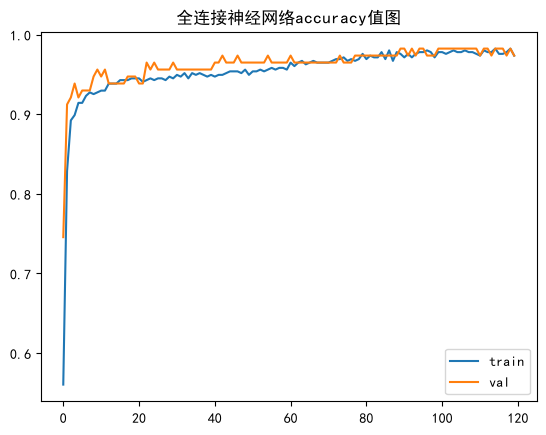

In [3]:
# 绘制训练集和验证集的loss值对比
plt.plot(history.history['loss'], label='train')
plt.plot(history.history['val_loss'], label='val')
plt.title("全连接神经网络loss值图")
plt.legend()
plt.show()

# 绘制训练集和验证集的准确率对比图
plt.plot(history.history['accuracy'], label='train')
plt.plot(history.history['val_accuracy'], label='val')
plt.title("全连接神经网络accuracy值图")
plt.legend()
plt.show()